# 01 — Cleaning the data and first look at the market

**Data:** one CSV from [Inside Airbnb](https://insideairbnb.com/get-the-data/)
— the Barcelona snapshot of **17 September 2026**: 15,236 listings, 19 columns.
Details and download steps: [`data/README.md`](../data/README.md).

**In this notebook:** check what is in the file, remove listings that cannot
be analysed, and take a first look at two policy levers the data can see:
the **tourist-licence phase-out** and the **seasonal-rental rules**.

**Population.** The website counts *listings with open dates* (at least one
open date in the next 365 days). An empty calendar can mean booked, blocked or
withdrawn, so this notebook says "open dates", not "active", and shows both
populations where they differ.

**Labels.** Listings are labelled only by the minimum stay they ask — under 31,
exactly 31, over 31 nights — never by legality. A minimum stay is a setting, not
a contract, an actual stay or a legal finding.

Each lever is read the same way: *what the rule says*, *what the data shows*,
*what the data cannot show*. No verdicts.

The cleaning rules live in [`src/cleaning.py`](../src/cleaning.py), with
tests in [`tests/test_cleaning.py`](../tests/test_cleaning.py).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config as cfg
from src import cleaning

sns.set_theme(style="whitegrid", palette="colorblind")
np.random.seed(cfg.SEED)

In [2]:
raw = cleaning.load_listings()
print(raw.shape)
raw.drop(columns=["license", "host_name"]).head(3)   # personal columns excluded on purpose

(15236, 19)


,id,name,host_id,host_profile_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,18674,Huge flat for 8 people close to Sagrada Familia,71615,1462508358342835057,Eixample,la Sagrada Família,41.40556,2.17262,Entire home/apt,274.0,1.0,60,2026-07-20,0.37,21,162,8
1,23197,CCIB Forum • Spacious 3BR • Large Balcony,90417,1462509351463595774,Sant Martí,el Besòs i el Maresme,41.41243,2.21975,Entire home/apt,408.0,3.0,102,2026-09-07,0.54,1,128,11
2,34981,VIDRE HOME PLAZA REAL on LAS RAMBLAS,73163,1462508447204147103,Ciutat Vella,el Barri Gòtic,41.37978,2.17623,Entire home/apt,546.0,1.0,314,2026-09-13,1.62,2,316,43


> **Privacy note:** under EU rules the `license` column can contain real
> host names and home addresses. This project never prints that raw text —
> `cleaning.regional_licence()` and `cleaning.national_licence()` turn it into
> safe categories, and those categories are all we ever use.

In [3]:
# How much is missing in each column?
raw.isna().sum().sort_values(ascending=False).head(6)

license                  5466
reviews_per_month        3301
last_review              3301
price                    2626
minimum_nights           2045
number_of_reviews_ltm       0
dtype: int64

Two columns have gaps that matter: `price` and `minimum_nights`.
Is either gap random? Check both against availability:

In [4]:
no_dates = raw["availability_365"] == 0

print(f"listings with zero available nights: {no_dates.sum():,}")
print(f"   share with no price:            {raw.loc[no_dates, 'price'].isna().mean():.1%}")
print(f"   share with no minimum stay:     {raw.loc[no_dates, 'minimum_nights'].isna().mean():.1%}")
print(f"listings WITH available nights:      {(~no_dates).sum():,}")
print(f"   share with no price:            {raw.loc[~no_dates, 'price'].isna().mean():.1%}")
print(f"   share with no minimum stay:     {raw.loc[~no_dates, 'minimum_nights'].isna().mean():.1%}")

listings with zero available nights: 3,499
   share with no price:            46.4%
   share with no minimum stay:     58.4%
listings WITH available nights:      11,737
   share with no price:            8.5%
   share with no minimum stay:     0.0%


Neither gap is random. **Every listing without a minimum stay has zero open
dates.** Prices are missing far more often among listings with no open dates
(46%) than among those with open dates (8.5%), but not only there: 62% of
all missing prices sit in no-open-date listings, and about 1,000 listings
with open dates have no price. So the price gap is concentrated in, not
confined to, listings with empty calendars. An empty calendar can mean booked,
blocked or withdrawn, so these listings are described as "no open dates", not
as off the market.

## Lever 1 — Seasonal rentals: the 31-night line

**What the rule says.** In Catalonia a tourist flat (HUT) is let for "a
continuous period of **31 days or fewer**" (Decret 75/2020, art. 221-1). A
longer stay falls outside that definition; seasonal lets (*lloguer de
temporada*) are a separate category. Since 1 January 2026 (Llei 11/2025) a
seasonal let that is not for exclusively holiday or leisure use counts as a
housing lease, so the stressed-zone rent limit applies to it. Parts of that law
are challenged at the Constitutional Court. Sources: `POLICY_LEVERS` in
`src/config.py`.

**What the data shows.** The most common minimum stays:

In [5]:
print(raw["minimum_nights"].value_counts().head(6).to_string())
print()
over_31 = raw["minimum_nights"] > cfg.STAY_LINE_NIGHTS
print(f"listings requiring more than {cfg.STAY_LINE_NIGHTS} nights: "
      f"{over_31.sum():,} ({over_31.mean():.1%} of all {len(raw):,} listings)")

# The same two values in the website's population: listings with open dates
open_dates = raw[raw["availability_365"] > 0]
at_31, at_32 = (open_dates["minimum_nights"] == 31).sum(), (open_dates["minimum_nights"] == 32).sum()
print(f"all listings in the file:   31 nights = {(raw['minimum_nights'] == 31).sum():,}, "
      f"32 nights = {(raw['minimum_nights'] == 32).sum():,}")
print(f"listings with open dates:   31 nights = {at_31:,}, 32 nights = {at_32:,} "
      f"({(at_31 + at_32) / len(open_dates):.1%} of {len(open_dates):,})")

minimum_nights
1.0     4525
32.0    2505
31.0    2504
2.0     2051
3.0      764
4.0      174

listings requiring more than 31 nights: 2,760 (18.1% of all 15,236 listings)
all listings in the file:   31 nights = 2,504, 32 nights = 2,505
listings with open dates:   31 nights = 2,293, 32 nights = 2,383 (39.8% of 11,737)


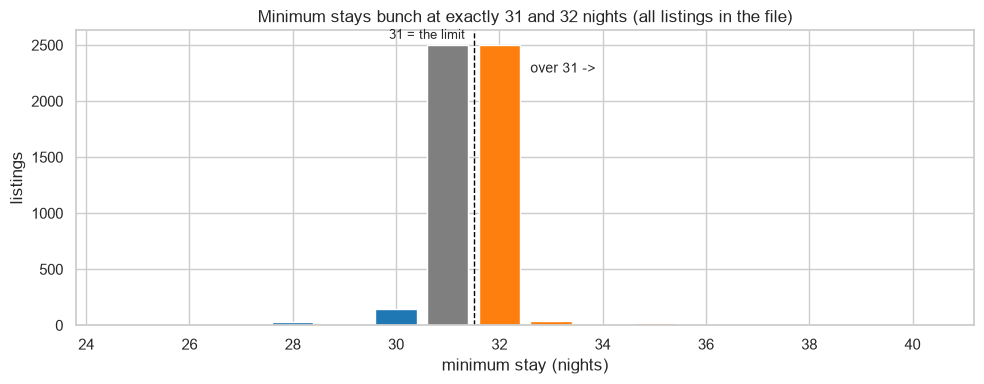

In [6]:
# Zoom in on the line: minimum stays from 25 to 40 nights
window = raw["minimum_nights"].between(25, 40)
counts = raw.loc[window, "minimum_nights"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
band_colors = {"under_31": "tab:blue", "exactly_31": "tab:gray", "over_31": "tab:orange"}
colors = [band_colors[b] for b in cleaning.stay_band(pd.Series(counts.index))]
ax.bar(counts.index.astype(int), counts.values, color=colors)
ax.axvline(cfg.STAY_LINE_NIGHTS + 0.5, color="black", linestyle="--", linewidth=1)
ax.text(cfg.STAY_LINE_NIGHTS + 1.6, counts.max() * 0.9, "over 31 ->", fontsize=10)
ax.text(cfg.STAY_LINE_NIGHTS - 0.4, counts.max() * 1.02, "31 = the limit", fontsize=9, ha="center")
ax.set_xlabel("minimum stay (nights)")
ax.set_ylabel("listings")
ax.set_title("Minimum stays bunch at exactly 31 and 32 nights (all listings in the file)")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "01_minimum_nights.png", dpi=150, bbox_inches="tight")

Minimum stays pile up on **31** and **32 nights**, with almost nothing
either side.

31 nights sits exactly on the legal limit, and whether a 31-night booking
counts as "31 days or fewer" is ambiguous. So listings are labelled only by
what they ask: `under_31` · `exactly_31` · `over_31`.

Hosts also *declare* how they are licensed. The licence field carries
two declarations: a regional one (Catalan licence, or *Exempt - seasonal
rental*) and a national one (NRUA code, whose letters say tourist `TU` or
non-tourist `NT`). Do the declarations match the minimum stay?

In [7]:
feat = cleaning.add_columns(raw)
feat = feat[feat["is_active"]]   # listings with open dates: the website's population
bands = ["under_31", "exactly_31", "over_31"]

def pct_by_band(column):
    table = pd.crosstab(feat[column], feat["stay_band"], normalize="columns") * 100
    return table[bands].round(1)

print("listings per band:", feat["stay_band"].value_counts()[bands].to_dict())
print()
print("regional licence, % of listings in each stay band:")
print(pct_by_band("regional_licence").to_string())
print()
print("national (NRUA) declaration, % of listings in each stay band:")
print(pct_by_band("national_licence").to_string())

listings per band: {'under_31': 6848, 'exactly_31': 2293, 'over_31': 2596}

regional licence, % of listings in each stay band:
stay_band         under_31  exactly_31  over_31
regional_licence                               
exempt_seasonal        0.0        57.7     48.2
hotel_or_hostel       10.1         0.0      0.0
missing               12.9        41.6     50.1
other_code             0.0         0.0      0.0
tourist_flat          76.9         0.7      1.7

national (NRUA) declaration, % of listings in each stay band:
stay_band         under_31  exactly_31  over_31
national_licence                               
exempt                 9.8         5.4      1.7
missing               23.2        48.3     41.8
nrua_seasonal          1.6        43.8     54.8
nrua_tourist          64.4         1.2      0.6
other                  1.0         1.3      1.2


The declarations line up with the minimum stay: listings asking under 31
nights mostly show an HUT licence and a tourist (`TU`) NRUA code; listings
asking over 31 mostly declare *Exempt - seasonal rental* and a non-tourist
(`NT`) code. **The exactly-31 group behaves like the over-31 one** — hosts who
ask exactly 31 nights almost never show an HUT licence.

A sizeable group shows **no regional licence at all** among listings asking
under 31 nights. Who are they?

In [8]:
no_licence = feat[(feat["stay_band"] == "under_31") & (feat["regional_licence"] == "missing")]
print(f"under-31 listings with no regional licence: {len(no_licence):,}")
print()
print(no_licence["room_type"].value_counts().to_string())
print()
print(f"with open dates:              {(no_licence['availability_365'] > 0).mean():.1%}")
print(f"reviewed in the last 12 months: {(no_licence['number_of_reviews_ltm'] > 0).mean():.1%}")

under-31 listings with no regional licence: 886

room_type
Entire home/apt    558
Private room       320
Hotel room           4
Shared room          4

with open dates:              100.0%
reviewed in the last 12 months: 63.7%


Most of them (63%) are **entire homes**, and a third are **private rooms**. An
HUT licence covers whole flats only (Llei 13/2002, art. 50 bis), so a room
cannot carry one. Every one of these listings has open dates and 64% were
reviewed in the last 12 months, so they are not dormant. The file cannot say
why the licence is not shown: the host may not have entered it, the field may
be empty for another reason, or the listing may be unlicensed. A missing
licence is therefore **not proof of an illegal listing**, and not proof of a
legal one either.

**What the data cannot show.** Bunching at 31–32 nights is *consistent with*
hosts positioning at the edge of the tourist-stay definition, but it is equally consistent
with genuine month-long lets (students, posted workers, medical stays). The
file has asking terms only: not who stayed, for how long, or at what rent.
It also cannot show whether a seasonal let respects the rent cap — that needs
the flat's size and the official reference index, which are not here.

## Lever 2 — Tourist-licence phase-out

**What the rule says.** Under Decret llei 3/2023, existing tourist flats (HUT)
in stressed municipalities, Barcelona included, must obtain an urban-planning
licence within five years — by **9 November 2028** — or stop operating. An
owner can request **one extension of up to five more years**. The
Constitutional Court dismissed the appeal against the decree in full
(STC 64/2025). Barcelona's council announced in June 2024 that it does not
plan to grant these licences (press reports, not a legal text), so most HUTs
are expected to lapse. The extension route means the end date may not be the
same for every flat.

**What the data shows.** How much of the current tourist market runs on an
HUT licence, and who holds those listings:

In [9]:
under_31 = feat[feat["stay_band"] == "under_31"]
hut = under_31[under_31["has_tourist_licence"]]

print(f"listings asking under 31 nights:           {len(under_31):,}")
print(f"   with an HUT licence:                   {len(hut):,} ({len(hut) / len(under_31):.1%})")
print(f"   of those, entire homes:                {hut['is_entire_home'].mean():.1%}")
print(f"   of those, run by hosts with 5+ listings: {hut['is_professional'].mean():.1%}")

listings asking under 31 nights:           6,848
   with an HUT licence:                   5,269 (76.9%)
   of those, entire homes:                89.5%
   of those, run by hosts with 5+ listings: 66.0%


In [10]:
# Where are the HUT listings?
by_district = (hut.groupby("neighbourhood_group")["id"].count()
                  .sort_values()
                  .rename("HUT listings"))
by_district.to_frame().assign(share=lambda d: (d["HUT listings"] / d["HUT listings"].sum() * 100).round(1))

,HUT listings,share
neighbourhood_group,,
Nou Barris,16,0.3
Sant Andreu,42,0.8
Horta-Guinardó,105,2.0
Les Corts,127,2.4
Sarrià-Sant Gervasi,172,3.3
Sant Martí,497,9.4
Gràcia,513,9.7
Sants-Montjuïc,660,12.5
Ciutat Vella,797,15.1


**What the data cannot show.** One HUT licence is one dwelling, but one
dwelling can appear in several listings, and some licensed flats are not on
Airbnb at all. So listing counts are not a count of licences — the official
register (Ajuntament / Generalitat open data) is the right source for that.
The data also cannot show what happens to these flats after 2028: return to
long-term rent, move to seasonal lets, sale, or legal challenge.

## Cleaning

Two rules, from `src/cleaning.py`: keep listings with **open dates** (the
website's population) and a usable price (> 0 and ≤ 1000 EUR). Every listing
with open dates has a minimum stay on file; the cleaning function asserts it. Unlike the Berlin project, **listings asking over 31 nights are
kept** — the rent limit on seasonal lets is one of the levers under study.

In [11]:
df = cleaning.clean_listings(raw)
df.to_csv(cfg.CLEAN_FILE, index=False)
print(f"\nsaved -> {cfg.CLEAN_FILE.name}")

start:                                  15,236 listings
with open dates (the site's population): 11,737
with a usable price (<= 1000 EUR):       10,439

saved -> listings_clean.csv


In [12]:
# Headline numbers, by stay band
summary = (df.groupby("stay_band")
             .agg(listings=("id", "count"),
                  median_price=("price", "median"),
                  entire_homes=("is_entire_home", "mean"))
             .loc[["under_31", "exactly_31", "over_31"]]
             .round(2))
summary

,listings,median_price,entire_homes
stay_band,,,
under_31,6399,245.0,0.77
exactly_31,1902,82.5,0.60
over_31,2138,72.0,0.63


## Who supplies this market?

Counting listings per host account (`host_id`) shows how concentrated the
market is. An account is not necessarily one owner or one company.

In [13]:
# Host accounts, counted on listings with open dates (the website's population).
# An account is not necessarily one owner or one company.
hosts = open_dates.dropna(subset=["host_id"]).groupby("host_id")["id"].count()

big = hosts[hosts >= cfg.PROFESSIONAL_MIN]
print(f"host accounts in total:        {len(hosts):,}")
print(f"accounts with 5+ listings:     {len(big):,}  ({len(big) / len(hosts):.1%} of accounts)")
print(f"listings they run:             {big.sum():,}  ({big.sum() / len(open_dates):.1%} of listings with open dates)")
print(f"largest single account runs:   {hosts.max()} listings")

host accounts in total:        3,516
accounts with 5+ listings:     465  (13.2% of accounts)
listings they run:             7,444  (63.4% of listings with open dates)
largest single account runs:   510 listings


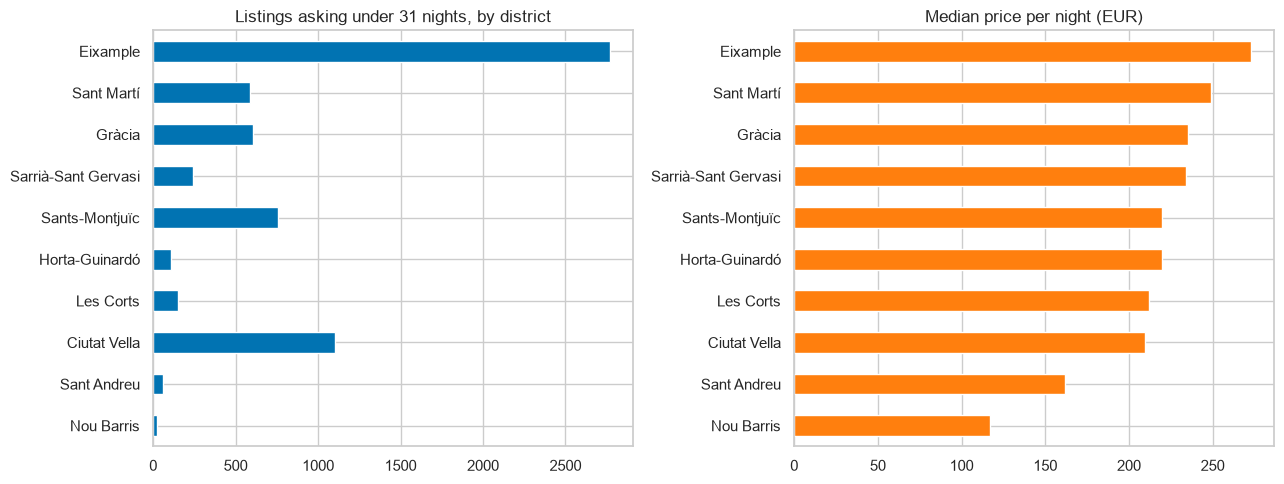

In [14]:
# Listings and median price by district (listings asking under 31 nights)
by_district = (df[df["stay_band"] == "under_31"]
                 .groupby("neighbourhood_group")
                 .agg(listings=("id", "count"), median_price=("price", "median"))
                 .sort_values("median_price"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_district["listings"].plot.barh(ax=axes[0], title="Listings asking under 31 nights, by district")
by_district["median_price"].plot.barh(ax=axes[1], color="tab:orange",
                                      title="Median price per night (EUR)")
for ax in axes:
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "01_districts.png", dpi=150, bbox_inches="tight")

## What I found

1. **Gaps follow the calendar.** Every missing minimum stay (13% of listings)
   is in a listing with no open dates; missing prices (17%) are concentrated
   there (62%) but also occur in about 1,000 listings with open dates.
2. **The market bunches at 31 and 32 nights.** In the whole file 2,504
   listings ask exactly 31 nights and 2,505 ask 32 (a third of all listings).
   Among the 11,737 listings with open dates it is 2,293 and 2,383, together
   39.8%.
3. **Listings asking exactly 31 nights look like those asking over 31.** Only
   0.7% of them show an HUT licence (vs 76.9% of those asking under 31), and
   their median asking price is €82.5 a night, close to over-31 (€72) and far
   from under-31 (€245).
4. **Declarations match the minimum stay.** 64.4% of under-31 listings show a
   tourist (`TU`) NRUA code; 54.8% of over-31 listings show a non-tourist
   (`NT`) code. 12.9% (886) of under-31 listings show no regional licence:
   63% of them are entire homes and 36% private rooms, all with open dates.
5. **The phase-out touches a concentrated, central slice.** 5,269 listings
   asking under 31 nights carry an HUT licence; 89.5% are entire homes, 66.0%
   belong to accounts with 5+ listings, and 60% are in Eixample or Ciutat
   Vella.
6. **Supply is concentrated.** 13.2% of host accounts run 5+ listings and run
   63.4% of the listings with open dates; the largest account runs 510. An
   account is not necessarily one owner or one company.

**Next:** `02_statistics.ipynb` — how sure are we about these numbers, and
which differences are real?